In [82]:
import os
# Evite le crash OpenMP quand PyTorch et OpenCV sont charges ensemble
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['OMP_NUM_THREADS'] = '1'

# Notebook 1 — Preprocessing & Visualisation (EDA)

**Objectif** : Nettoyer les données, analyser le dataset Rakuten (84 916 produits, 27 classes)  
et préparer toutes les features de base pour la modélisation.

**Livrables** :
- `data/split_no_crop/{train,val,test}.csv` — splits stratifiés avec toutes les features texte
- `data/processed_clean/` — features numériques, labels encodés, class weights
- `data/processed_clean/image_crop/` — images recadrées (auto-crop)
- `reports/figures/` — graphiques EDA exportés

---

## 0. Configuration (CFG)

In [83]:
from pathlib import Path

# Detecte automatiquement la racine du projet (remonte 2 niveaux depuis notebooks/main_notebooks/)
_NB_DIR = Path('__file__').resolve().parent if '__file__' in dir() else Path.cwd()
ROOT = _NB_DIR
for _ in range(5):  # cherche le dossier racine jusqu'a 5 niveaux au-dessus
    if (ROOT / 'data' / 'raw').exists():
        break
    ROOT = ROOT.parent

CFG = {
    # --- Repertoires ---
    'root':            ROOT,
    'data_raw':        ROOT / 'data' / 'raw',
    'images_train':    ROOT / 'data' / 'raw' / 'images' / 'image_train',
    'processed':       ROOT / 'data' / 'processed_clean',
    'split_dir':       ROOT / 'data' / 'split_no_crop2',
    'models_dir':      ROOT / 'models' / 'clean',
    'figures_dir':     ROOT / 'reports' / 'figures',

    # --- Preprocessing texte ---
    'languages':       ['fr', 'en', 'de', 'es'],
    'min_text_len':    5,        # nb chars minimum pour detecter la langue
    'tfidf_max_feat':  50_000,
    'tfidf_ngram':     (1, 2),

    # --- Preprocessing images ---
    'blur_threshold':  100.0,    # variance Laplacien : en dessous = flou
    'white_threshold': 240,      # valeur pixel (0-255) consideree comme blanche
    'bg_ratio_thresh': 0.70,     # ratio fond blanc au-dela duquel l'image est 'dezoomee'
    'crop_margin_pct': 0.02,     # marge apres auto-crop (fraction de la taille)

    # --- Split ---
    'val_size':        0.15,
    'test_size':       0.15,
    'random_state':    42,
    'n_classes':       27,
}

# Creation des repertoires de sortie
for d in ['processed', 'split_dir', 'models_dir', 'figures_dir']:
    CFG[d].mkdir(parents=True, exist_ok=True)
(CFG['processed'] / 'image_crop').mkdir(parents=True, exist_ok=True)

print(f"ROOT : {CFG['root']}")
print(f"data/raw    : {CFG['data_raw'].exists()}")
print(f"images_train: {CFG['images_train'].exists()}")

ROOT : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten
data/raw    : True
images_train: True


## 1. Imports

In [84]:
%matplotlib inline

# Core
import re
import pickle
import logging
import textwrap
from collections import Counter

# Data
import numpy as np
import pandas as pd
import scipy.sparse as sp

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from wordcloud import WordCloud

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.snowball import SnowballStemmer

# Image
from PIL import Image, UnidentifiedImageError
import torchvision.transforms as T
from tqdm.auto import tqdm

# ML
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.stats import chisquare, chi2_contingency, kruskal

# Detection de langue
from py3langid.langid import LanguageIdentifier, MODEL_FILE

logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(message)s')
sns.set_theme(style='whitegrid', palette='muted')
tqdm.pandas()

# Ressources NLTK
for resource in ['stopwords', 'punkt_tab']:
    nltk.download(resource, quiet=True)

In [85]:
def save_fig(name: str, dpi: int = 150) -> None:
    """Sauvegarde la figure courante dans reports/figures/."""
    path = CFG['figures_dir'] / name
    plt.savefig(path, dpi=dpi, bbox_inches='tight')
    logging.info(f'Figure sauvegardee : {path}')

---
## 2. Chargement des données

In [86]:
# Mapping prdtypecode -> nom de classe lisible
CLASS_NAMES = {
    10:   'Livres occasion',
    40:   'Jeux video',
    50:   'Accessoires gaming',
    60:   'Consoles de jeux',
    1140: 'Figurines',
    1160: 'Cartes collection',
    1180: 'Jeux de societe',
    1281: 'Jeux enfants',
    1300: 'Miniatures vehicules',
    1301: 'Bebe / Puericulture',
    1302: 'Jeux plein air',
    1320: 'Puériculture & Peluches',
    1560: 'Mobilier',
    1920: 'Linge maison',
    1940: 'Epicerie',
    2060: 'Décoration',
    2220: 'Animalerie',
    2280: 'Journaux / Revues',
    2403: 'Livres neufs',
    2462: 'Jeux PC dématérialisés',
    2522: 'Papeterie / Bureautique',
    2582: 'Piscines / Spas',
    2583: 'Outillage jardinage',
    2585: 'Bricolage',
    2705: 'Livres BD / Mangas',
    2905: 'Jeux de role',
    1970: 'Cuisine / Electroménager',
}

In [87]:
X_raw = pd.read_csv(CFG['data_raw'] / 'X_train_update.csv', index_col=0)
y_raw = pd.read_csv(CFG['data_raw'] / 'Y_train.csv', index_col=0)
X_test_raw = pd.read_csv(CFG['data_raw'] / 'X_test_update.csv', index_col=0)

df = X_raw.join(y_raw, how='left')
df['class_name'] = df['prdtypecode'].map(CLASS_NAMES)

# Nettoyage bas niveau des types
df['designation']  = df['designation'].astype(str).str.strip()
df['description']  = df['description'].where(df['description'].notna(), other=None)

print(f'Shape train : {df.shape}')
print(f'Classes     : {df["prdtypecode"].nunique()}')
print(f'Colonnes    : {df.columns.tolist()}')
df.head(3)

Shape train : (84916, 6)
Classes     : 27
Colonnes    : ['designation', 'description', 'productid', 'imageid', 'prdtypecode', 'class_name']


,designation,description,productid,imageid,prdtypecode,class_name
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,10,Livres occasion
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,2280,Journaux / Revues
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,50,Accessoires gaming


---
## 3. EDA — Analyse Texte

### 3.1 Répartition des classes

C:\Users\veyss\AppData\Local\Temp\ipykernel_26528\1504549162.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.values, y=class_counts.index, palette='muted', ax=ax1)
2026-05-17 15:53:17,717 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph01_class_distribution.png


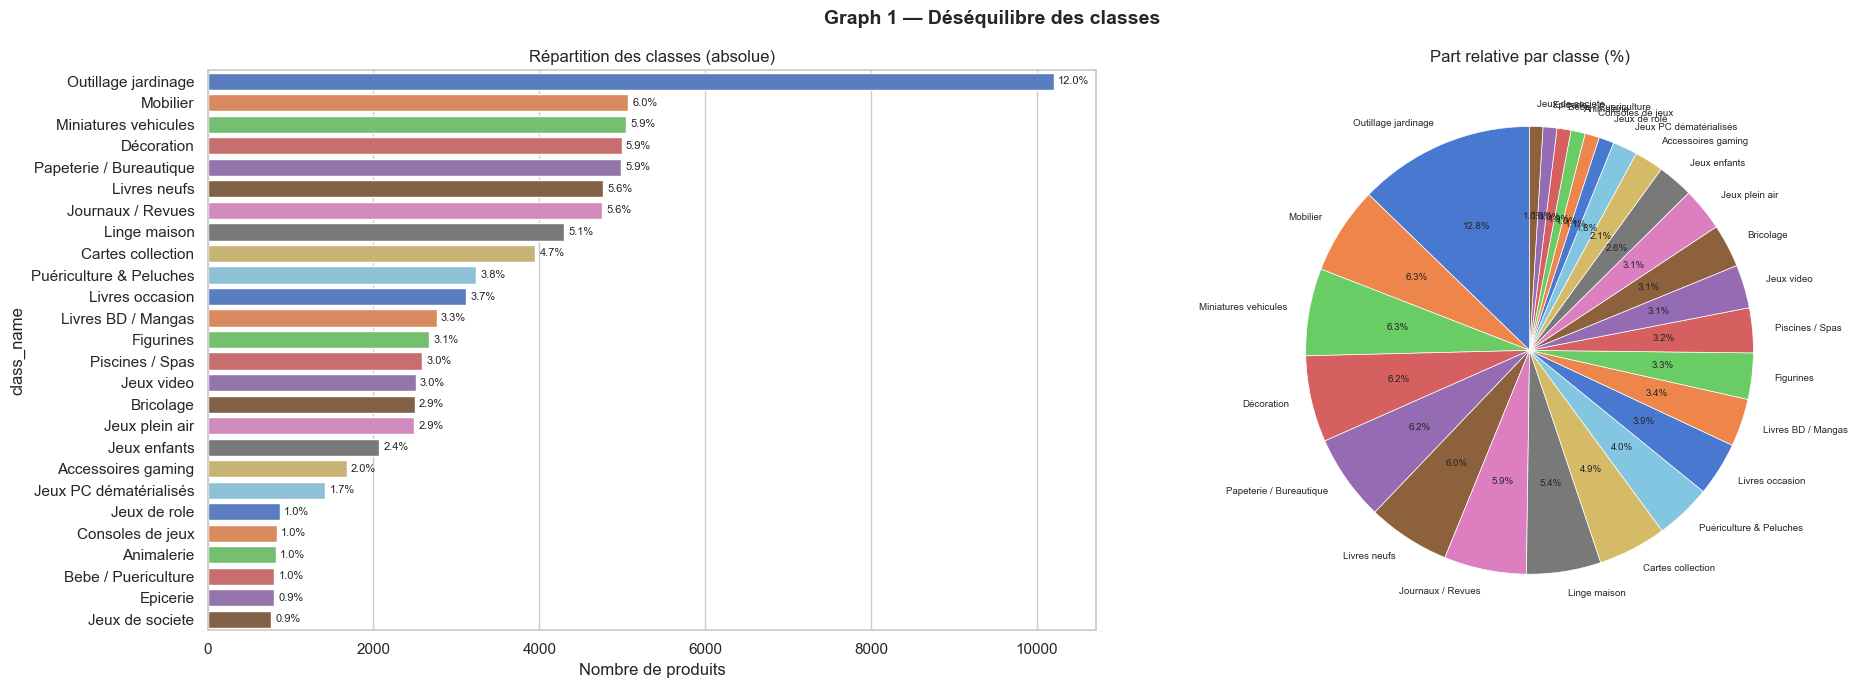


Test Chi2 (distribution uniforme) : chi2=36355, p=0.00e+00
  → Desequilibre statistiquement confirme (p<<0.05)
  Classe la plus frequente : Outillage jardinage (12.0%)
  Classe la plus rare      : Jeux de societe (0.9%)
  Ratio max/min            : 13.4x


In [88]:
class_counts = df['class_name'].value_counts()
pct_class = class_counts / len(df) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 7))

# Barplot horizontal
colors = plt.cm.tab20.colors
sns.barplot(x=class_counts.values, y=class_counts.index, palette='muted', ax=ax1)
ax1.set_xlabel('Nombre de produits')
ax1.set_title('Répartition des classes (absolue)')
for i, v in enumerate(class_counts.values):
    ax1.text(v + 50, i, f'{pct_class.iloc[i]:.1f}%', va='center', fontsize=8)

# Pie chart
wedge_props = {'linewidth': 0.5, 'edgecolor': 'white'}
ax2.pie(class_counts.values, labels=class_counts.index,
        autopct='%1.1f%%', startangle=90,
        wedgeprops=wedge_props, textprops={'fontsize': 7})
ax2.set_title('Part relative par classe (%)')

plt.suptitle('Graph 1 — Déséquilibre des classes', fontsize=14, fontweight='bold')
plt.tight_layout()
save_fig('graph01_class_distribution.png')
plt.show()

# Test chi2
observed = class_counts.values
expected = np.full(len(observed), observed.sum() / len(observed))
chi2_stat, p_val = chisquare(f_obs=observed, f_exp=expected)
print(f'\nTest Chi2 (distribution uniforme) : chi2={chi2_stat:.0f}, p={p_val:.2e}')
print(f'  → Desequilibre statistiquement confirme (p<<0.05)')
print(f'  Classe la plus frequente : {class_counts.index[0]} ({pct_class.iloc[0]:.1f}%)')
print(f'  Classe la plus rare      : {class_counts.index[-1]} ({pct_class.iloc[-1]:.1f}%)')
print(f'  Ratio max/min            : {class_counts.values[0]/class_counts.values[-1]:.1f}x')

### 3.2 Détection de la langue

In [89]:
identifier = LanguageIdentifier.from_pickled_model(MODEL_FILE, norm_probs=True)
identifier.set_languages(CFG['languages'])

def detect_lang(text: str) -> str:
    if pd.isna(text) or len(str(text).strip()) < CFG['min_text_len']:
        return 'unknown'
    lang, _prob = identifier.classify(str(text))
    return lang

print('Detection langue en cours...')
df['language'] = df['designation'].progress_apply(detect_lang)

lang_counts = df['language'].value_counts()
print('\nDistribution langues :')
print(lang_counts)

Detection langue en cours...


100%|██████████| 84916/84916 [00:02<00:00, 28376.16it/s]


Distribution langues :
language
fr    65996
en    12975
es     3101
de     2844
Name: count, dtype: int64


2026-05-17 15:53:21,895 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph02_language_distribution.png


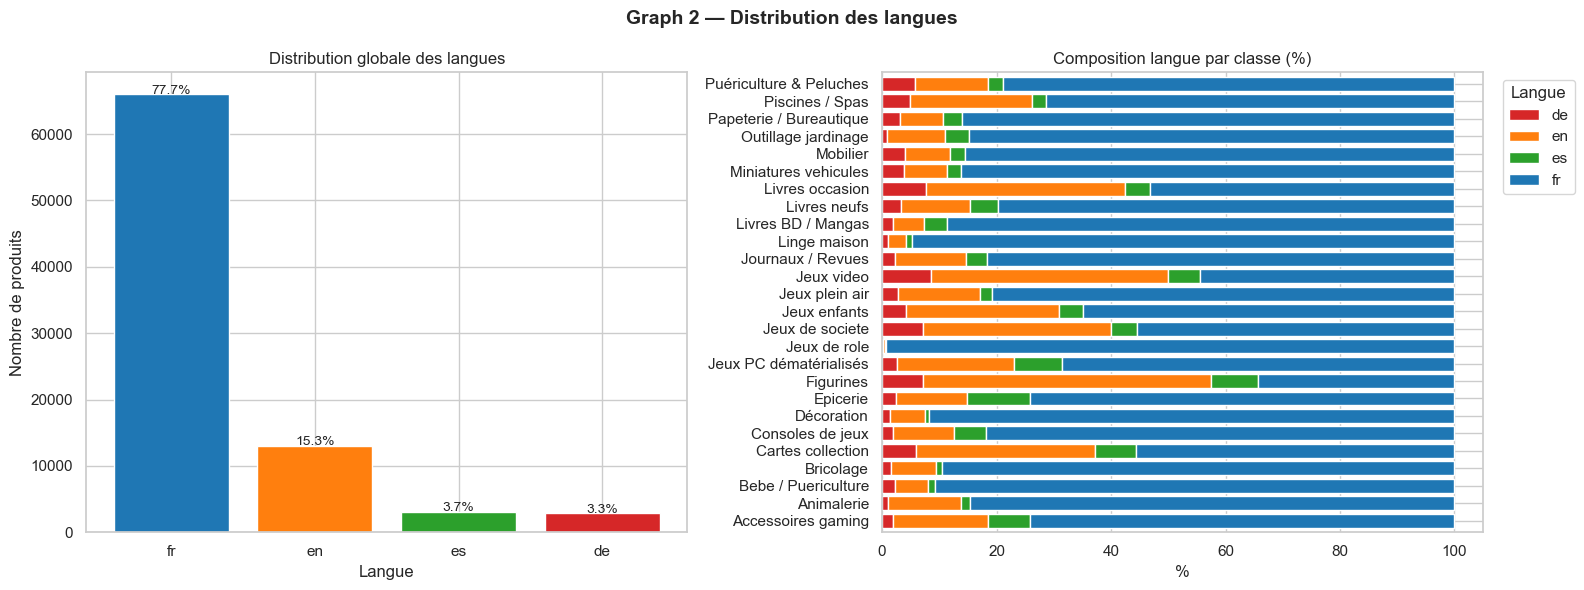

Test Chi2 (langue x classe) : chi2=11727, p=0.00e+00, dof=78
  → La distribution des langues depend significativement de la classe


In [90]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Distribution globale
lang_colors = {lang: plt.cm.tab10.colors[i] for i, lang in enumerate(lang_counts.index)}
ax1.bar(lang_counts.index, lang_counts.values,
        color=[lang_colors[l] for l in lang_counts.index])
ax1.set_title('Distribution globale des langues')
ax1.set_xlabel('Langue')
ax1.set_ylabel('Nombre de produits')
for i, (l, v) in enumerate(zip(lang_counts.index, lang_counts.values)):
    ax1.text(i, v + 100, f'{v/len(df)*100:.1f}%', ha='center', fontsize=10)

# Stacked barplot : langue par classe
lang_by_class = (df.groupby(['class_name', 'language'])
                 .size().unstack(fill_value=0))
lang_by_class_pct = lang_by_class.div(lang_by_class.sum(axis=1), axis=0) * 100
lang_by_class_pct.plot(kind='barh', stacked=True, ax=ax2, width=0.8,
                        color=[lang_colors.get(c, 'grey') for c in lang_by_class_pct.columns])
ax2.set_title('Composition langue par classe (%)')
ax2.set_xlabel('%')
ax2.set_ylabel('')
ax2.legend(title='Langue', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle('Graph 2 — Distribution des langues', fontsize=14, fontweight='bold')
plt.tight_layout()
save_fig('graph02_language_distribution.png')
plt.show()

# Test chi2 langue x classe
contingency = pd.crosstab(df['prdtypecode'], df['language'])
chi2, p, dof, _ = chi2_contingency(contingency)
print(f'Test Chi2 (langue x classe) : chi2={chi2:.0f}, p={p:.2e}, dof={dof}')
print(f'  → La distribution des langues depend significativement de la classe')

### 3.3 Longueur des textes

In [91]:
df['len_desig'] = df['designation'].str.split().str.len().fillna(0).astype(int)
df['len_desc']  = df['description'].str.split().str.len().fillna(0).astype(int)

print('Longueur DESIGNATION (mots) :')
print(df['len_desig'].describe().round(1))
print('\nLongueur DESCRIPTION (mots) :')
print(df['len_desc'].describe().round(1))

Longueur DESIGNATION (mots) :
count    84916.0
mean        11.6
std          6.2
min          3.0
25%          7.0
50%         11.0
75%         14.0
max         56.0
Name: len_desig, dtype: float64

Longueur DESCRIPTION (mots) :
count    84916.0
mean        80.2
std        115.4
min          0.0
25%          0.0
50%         35.0
75%        125.0
max       2068.0
Name: len_desc, dtype: float64


2026-05-17 15:53:29,154 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph03_text_length_by_class.png


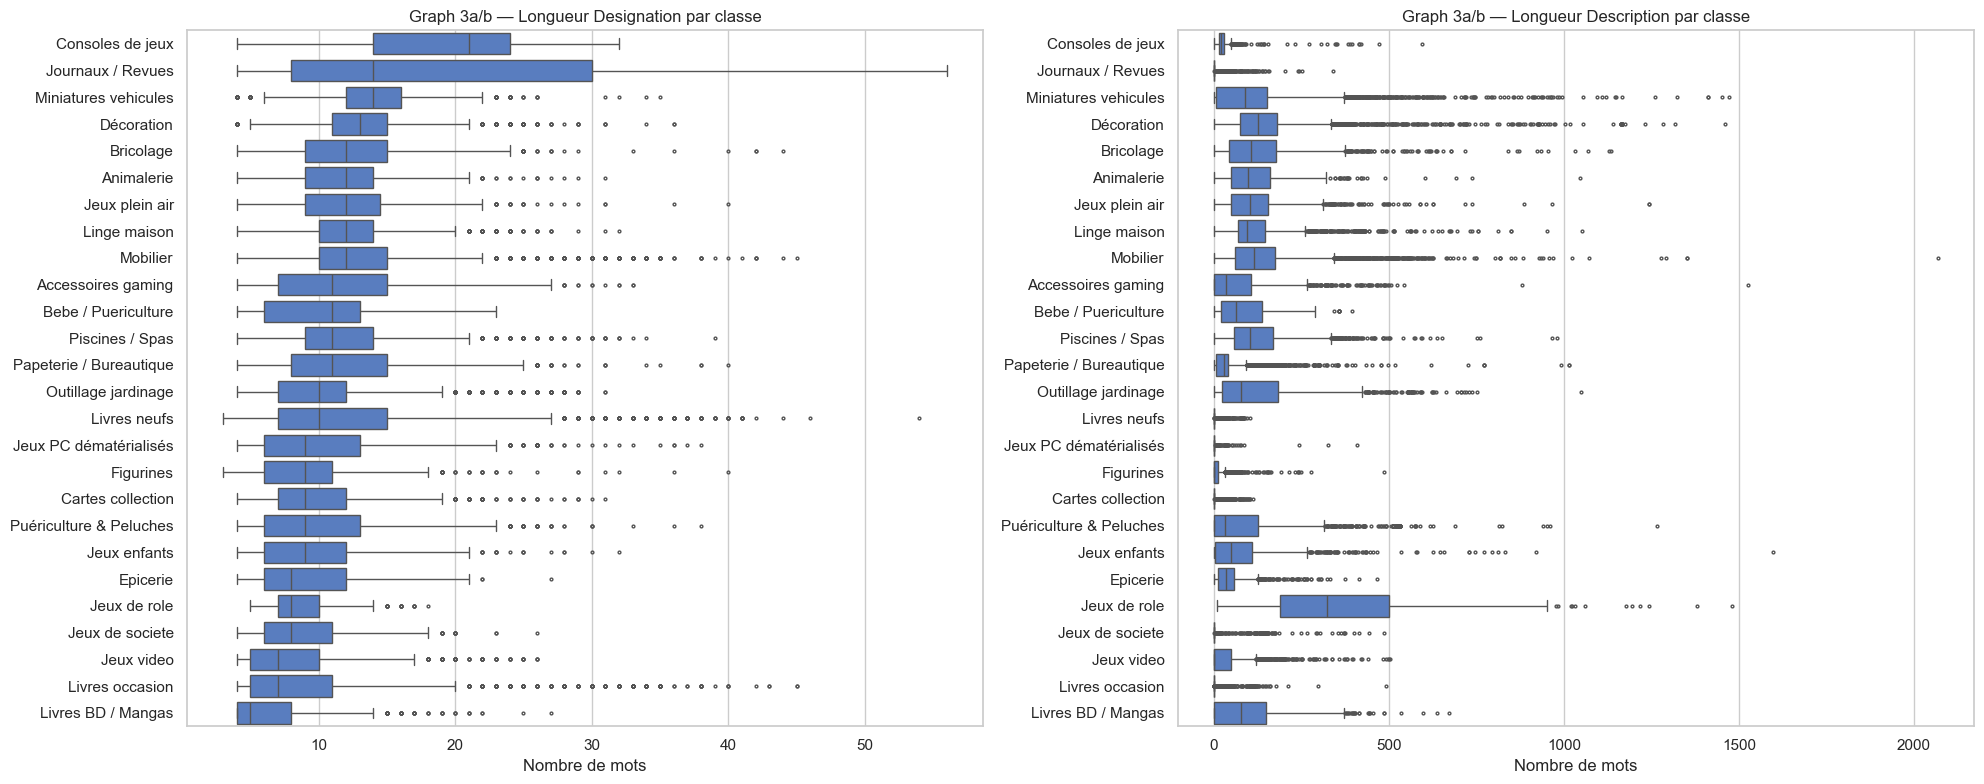

Kruskal-Wallis designation : H=13667.7, p=0.00e+00
Kruskal-Wallis description : H=39956.6, p=0.00e+00


In [92]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

order = df.groupby('class_name')['len_desig'].median().sort_values(ascending=False).index

for ax, col, title in zip(axes,
                           ['len_desig', 'len_desc'],
                           ['Designation', 'Description']):
    sns.boxplot(data=df, x=col, y='class_name', order=order, ax=ax, fliersize=2)
    ax.set_title(f'Graph 3a/b — Longueur {title} par classe')
    ax.set_xlabel('Nombre de mots')
    ax.set_ylabel('')

plt.tight_layout()
save_fig('graph03_text_length_by_class.png')
plt.show()

# Kruskal-Wallis : les longueurs different-elles entre classes ?
groups_d = [g['len_desig'].values for _, g in df.groupby('class_name')]
groups_desc = [g['len_desc'].values for _, g in df.groupby('class_name')]
kw_d = kruskal(*groups_d)
kw_desc = kruskal(*groups_desc)
print(f'Kruskal-Wallis designation : H={kw_d.statistic:.1f}, p={kw_d.pvalue:.2e}')
print(f'Kruskal-Wallis description : H={kw_desc.statistic:.1f}, p={kw_desc.pvalue:.2e}')

### 3.4 Descriptions manquantes par classe

2026-05-17 15:53:29,752 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph04_missing_desc_by_class.png


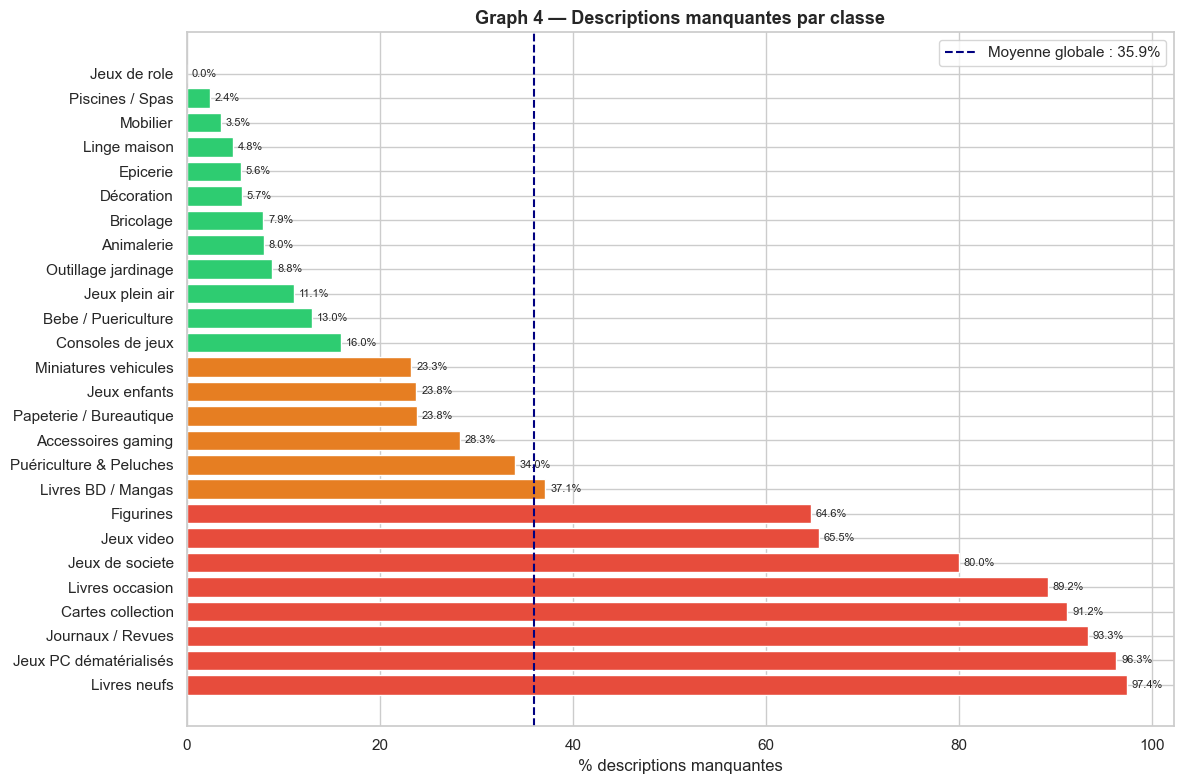

Taux global descriptions manquantes : 35.1%
Test Chi2 (has_desc x classe) : chi2=42927, p=0.00e+00
  → La presence de description depend significativement de la classe


In [93]:
df['has_desc'] = df['description'].notna().astype(int)

nan_by_class = (
    df.groupby('class_name')['description']
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 8))
colors_nan = ['#e74c3c' if v > 50 else '#e67e22' if v > 20 else '#2ecc71'
              for v in nan_by_class.values]
bars = ax.barh(nan_by_class.index, nan_by_class.values, color=colors_nan)
ax.axvline(nan_by_class.mean(), color='navy', linestyle='--', linewidth=1.5,
           label=f'Moyenne globale : {nan_by_class.mean():.1f}%')
ax.set_xlabel('% descriptions manquantes')
ax.set_title('Graph 4 — Descriptions manquantes par classe', fontsize=13, fontweight='bold')
ax.legend()
for bar, val in zip(bars, nan_by_class.values):
    ax.text(val + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=8)
plt.tight_layout()
save_fig('graph04_missing_desc_by_class.png')
plt.show()

# Test chi2 : presence description depend-elle de la classe ?
ct = pd.crosstab(df['class_name'], df['has_desc'])
chi2, p, dof, _ = chi2_contingency(ct)
print(f'Taux global descriptions manquantes : {df["description"].isna().mean()*100:.1f}%')
print(f'Test Chi2 (has_desc x classe) : chi2={chi2:.0f}, p={p:.2e}')
print(f'  → La presence de description depend significativement de la classe')

### 3.5 Nuages de mots et vocabulaire

In [94]:
# Construction du set de stop words multilingue (FR + EN + DE + ES)
all_stopwords = set()
lang_map = {'french': 'fr', 'english': 'en', 'german': 'de', 'spanish': 'es'}
for lang_name in lang_map:
    all_stopwords.update(stopwords.words(lang_name))
# Ajout de stopwords specifiques marketplace
all_stopwords.update(['cm', 'mm', 'ml', 'kg', 'g', 'l', 'n', 'x', 'ref', 'ref.', 'lot',
                       'pack', 'set', 'new', 'neuf', 'article', 'produit', 'product'])

def tokenize_no_stop(text: str) -> list:
    if pd.isna(text):
        return []
    tokens = word_tokenize(str(text).lower())
    return [t for t in tokens if t.isalpha() and t not in all_stopwords and len(t) > 2]

print(f'Taille vocabulaire stop words : {len(all_stopwords)}')

Taille vocabulaire stop words : 877


2026-05-17 15:54:08,840 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph05_wordclouds.png


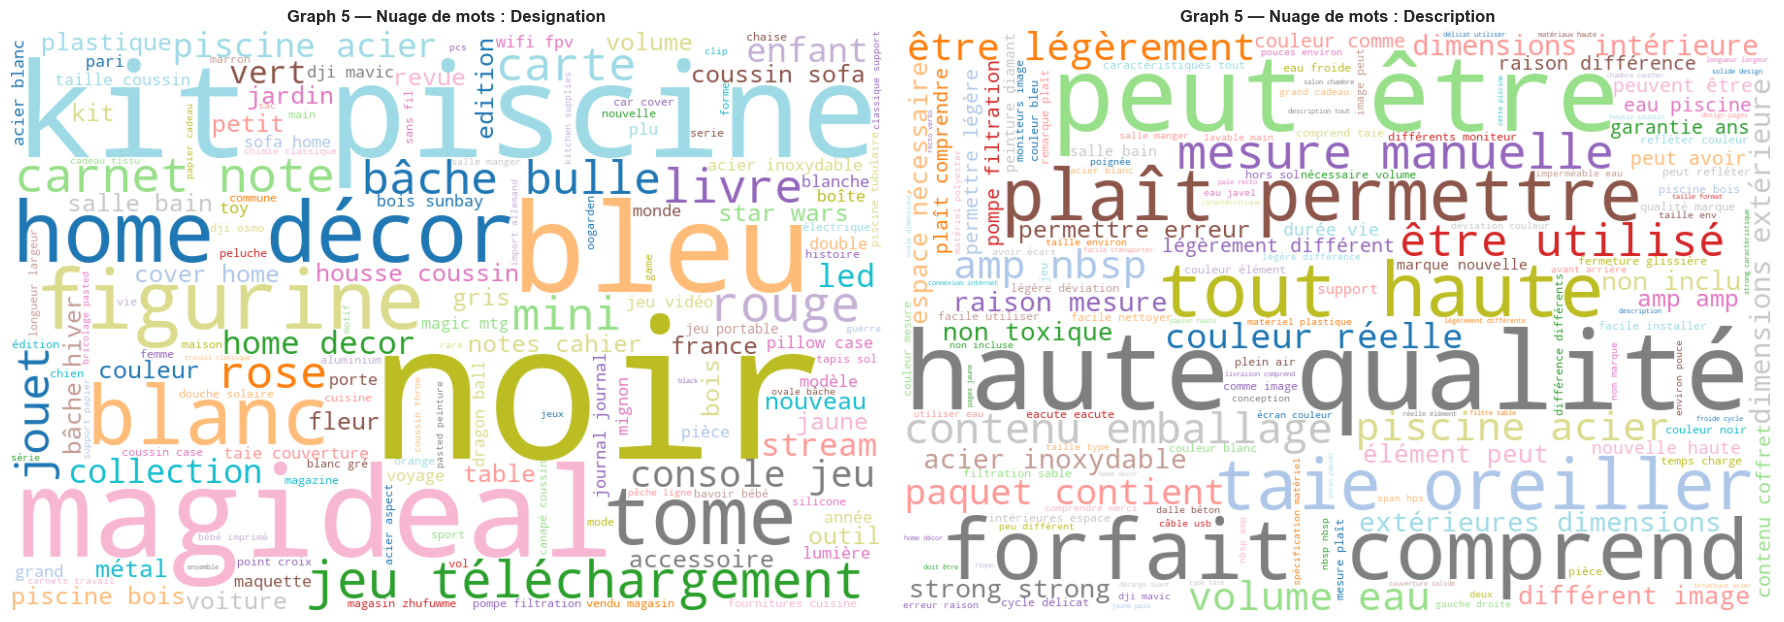

In [95]:
text_desig_all = ' '.join(df['designation'].dropna().apply(lambda x: ' '.join(tokenize_no_stop(x))))
text_desc_all  = ' '.join(df['description'].dropna().apply(lambda x: ' '.join(tokenize_no_stop(x))))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, text, title in zip(axes,
                            [text_desig_all, text_desc_all],
                            ['Designation', 'Description']):
    wc = WordCloud(width=900, height=600, background_color='white',
                   max_words=150, colormap='tab20').generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'Graph 5 — Nuage de mots : {title}', fontsize=12, fontweight='bold')

plt.tight_layout()
save_fig('graph05_wordclouds.png')
plt.show()

2026-05-17 15:54:10,346 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph05b_top_words_per_class.png


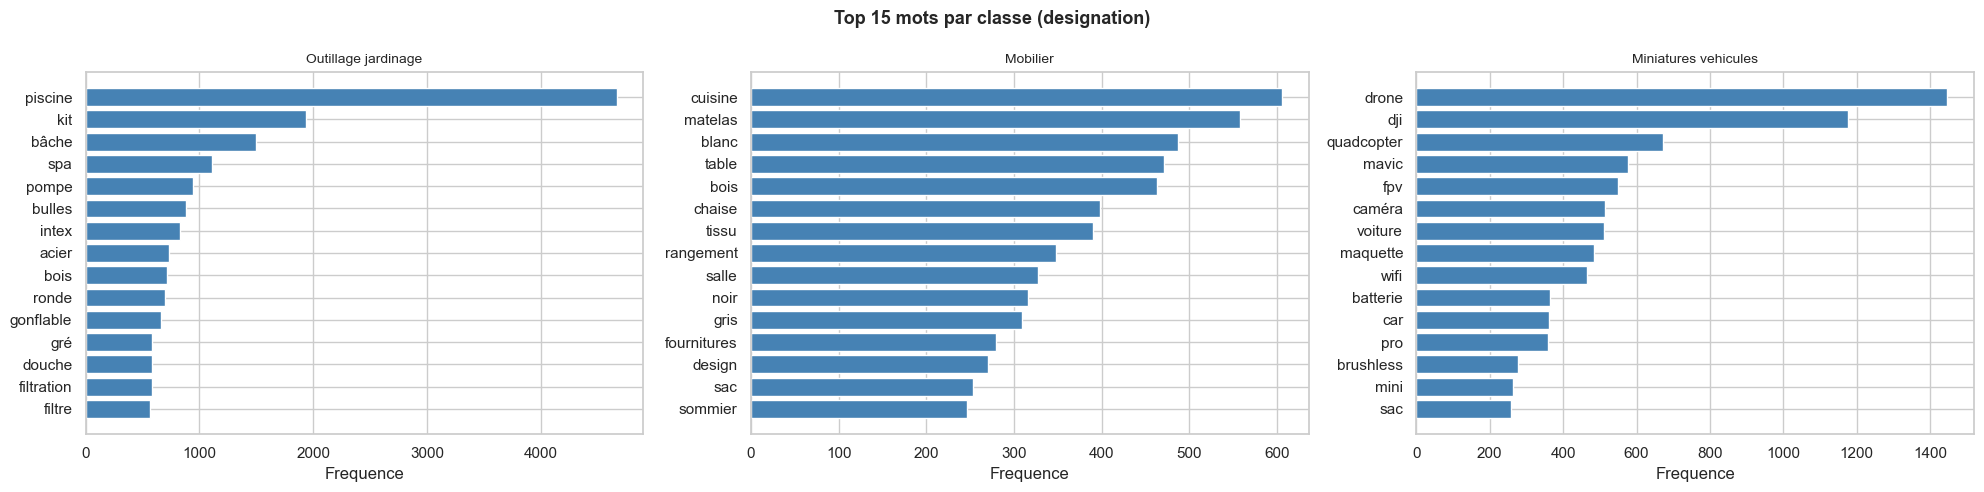

In [96]:
# Top 3 classes : vocabulaire distinctif
top3_classes = df['class_name'].value_counts().head(3).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, cls in zip(axes, top3_classes):
    subset = df[df['class_name'] == cls]['designation']
    tokens = [t for text in subset for t in tokenize_no_stop(text)]
    mc = Counter(tokens).most_common(15)
    if mc:
        mots, freq = zip(*mc)
        ax.barh(mots[::-1], freq[::-1], color='steelblue')
        ax.set_title(cls, fontsize=10)
        ax.set_xlabel('Frequence')

plt.suptitle('Top 15 mots par classe (designation)', fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('graph05b_top_words_per_class.png')
plt.show()

### 3.6 Heatmap longueur x langue

2026-05-17 15:54:10,893 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph06_length_lang_heatmap.png


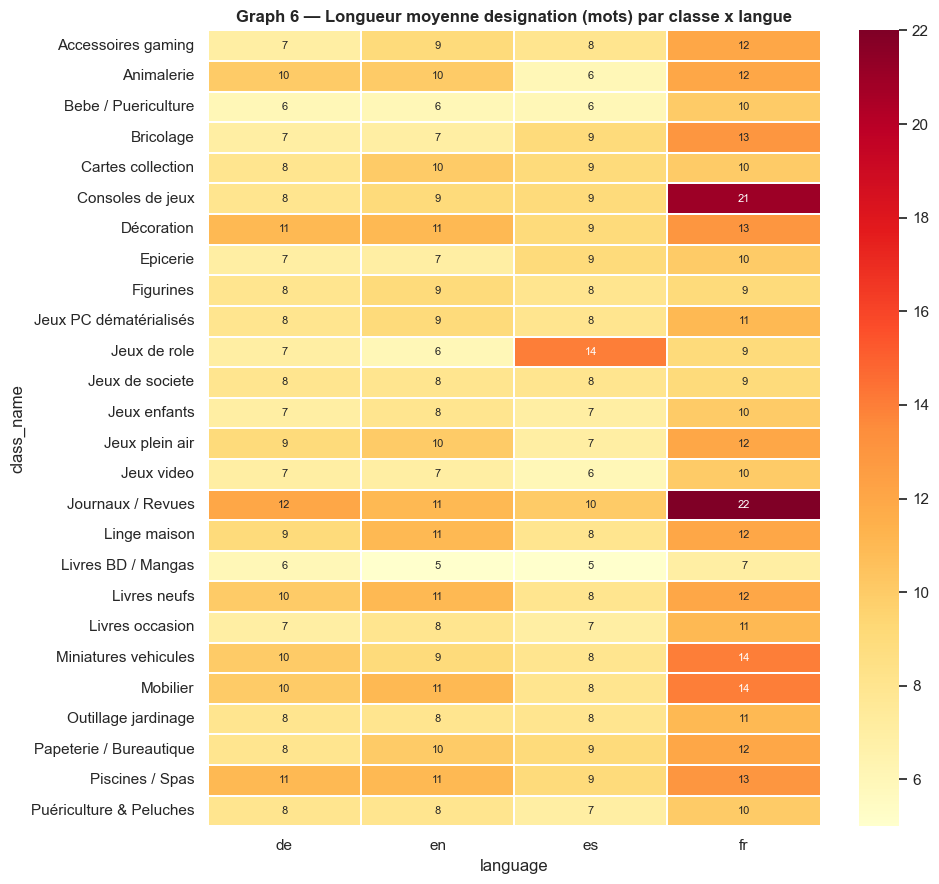

In [97]:
pivot = (df.groupby(['class_name', 'language'])['len_desig']
         .mean().unstack(fill_value=0).round(0))

plt.figure(figsize=(10, 9))
sns.heatmap(pivot, cmap='YlOrRd', fmt='.0f', linewidths=0.3, annot=True, annot_kws={'size': 8})
plt.title('Graph 6 — Longueur moyenne designation (mots) par classe x langue',
          fontsize=12, fontweight='bold')
plt.tight_layout()
save_fig('graph06_length_lang_heatmap.png')
plt.show()

### 3.7 Tableau de statistiques descriptives par classe

In [98]:
stats_table = df.groupby('class_name').agg(
    nb_produits          = ('designation', 'count'),
    pct_desc_manquante   = ('has_desc', lambda x: round((1 - x.mean()) * 100, 1)),
    len_desig_median     = ('len_desig', 'median'),
    len_desc_median      = ('len_desc', 'median'),
    lang_fr_pct          = ('language', lambda x: round((x == 'fr').mean() * 100, 1)),
).sort_values('nb_produits', ascending=False)

stats_table.columns = ['N produits', '% desc. manquante', 'Median mots désig.',
                        'Median mots desc.', '% FR']
stats_table.to_csv(CFG['processed'] / 'stats_par_classe.csv')
stats_table

,N produits,% desc. manquante,Median mots désig.,Median mots desc.,% FR
class_name,,,,,
Outillage jardinage,10209,8.8,10.0,76.0,84.9
Mobilier,5073,3.5,12.0,114.0,85.5
Miniatures vehicules,5045,23.3,14.0,88.0,86.2
Décoration,4993,5.7,13.0,127.0,91.8
Papeterie / Bureautique,4989,23.8,11.0,28.0,86.1
Livres neufs,4774,97.4,10.0,0.0,79.7
Journaux / Revues,4760,93.3,14.0,0.0,81.7
Linge maison,4303,4.8,12.0,95.0,94.8
Cartes collection,3953,91.2,9.0,0.0,55.7


---
## 4. EDA — Analyse Images

### 4.1 Flou (variance Laplacien)

In [99]:
def compute_blur_score(image_path: Path) -> float:
    """Variance du Laplacien via PIL + scipy (pas besoin de cv2)."""
    try:
        from scipy.ndimage import convolve
        gray = np.array(Image.open(image_path).convert('L'), dtype=np.float32)
        kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
        return float(convolve(gray, kernel).var())
    except Exception:
        return np.nan


def compute_white_ratio(image_path: Path, threshold: int = 240) -> float:
    """Calcule le ratio de pixels 'blancs' (fond vide) dans l'image."""
    try:
        img = np.array(Image.open(image_path).convert('RGB'))
        is_white = np.all(img >= threshold, axis=2)  # True si pixel >= seuil sur R,G,B
        return is_white.mean()
    except Exception:
        return np.nan


def build_image_name(row: pd.Series) -> str:
    return f"image_{row['imageid']}_product_{row['productid']}.jpg"

df['image_name'] = df.apply(build_image_name, axis=1)

print(f'Nombre d images attendues : {len(df)}')
n_exist = sum(1 for name in df['image_name'] if (CFG['images_train'] / name).exists())
print(f'Images trouvees           : {n_exist} ({n_exist/len(df)*100:.1f}%)')

Nombre d images attendues : 84916
Images trouvees           : 84916 (100.0%)


In [100]:
# Scan sur un echantillon strategique (N par classe) pour la visualisation
# Le scan complet sera fait en section 4.3 (auto-crop) et sauvegarde
N_SAMPLE_PER_CLASS = 20  # Augmenter pour une analyse plus exhaustive

sample_df = (df.groupby('prdtypecode', group_keys=False)
             .apply(lambda g: g.sample(min(N_SAMPLE_PER_CLASS, len(g)),
                                       random_state=CFG['random_state'])))

blur_records = []
for _, row in tqdm(sample_df.iterrows(), total=len(sample_df), desc='Calcul flou'):
    path = CFG['images_train'] / row['image_name']
    blur_records.append({
        'image_name': row['image_name'],
        'class_name': row['class_name'],
        'blur_score': compute_blur_score(path),
        'white_ratio': compute_white_ratio(path, CFG['white_threshold']),
    })

blur_df = pd.DataFrame(blur_records)
print(f'Score de flou moyen : {blur_df["blur_score"].median():.1f}')
print(f'Ratio fond blanc moyen : {blur_df["white_ratio"].mean():.2f}')
print(f'Images floues (score < {CFG["blur_threshold"]}) : {(blur_df["blur_score"] < CFG["blur_threshold"]).mean()*100:.1f}%')

Calcul flou: 100%|██████████| 540/540 [00:05<00:00, 104.32it/s]

Score de flou moyen : 619.9
Ratio fond blanc moyen : 0.51
Images floues (score < 100.0) : 7.4%


2026-05-17 15:54:25,298 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph07_image_quality.png


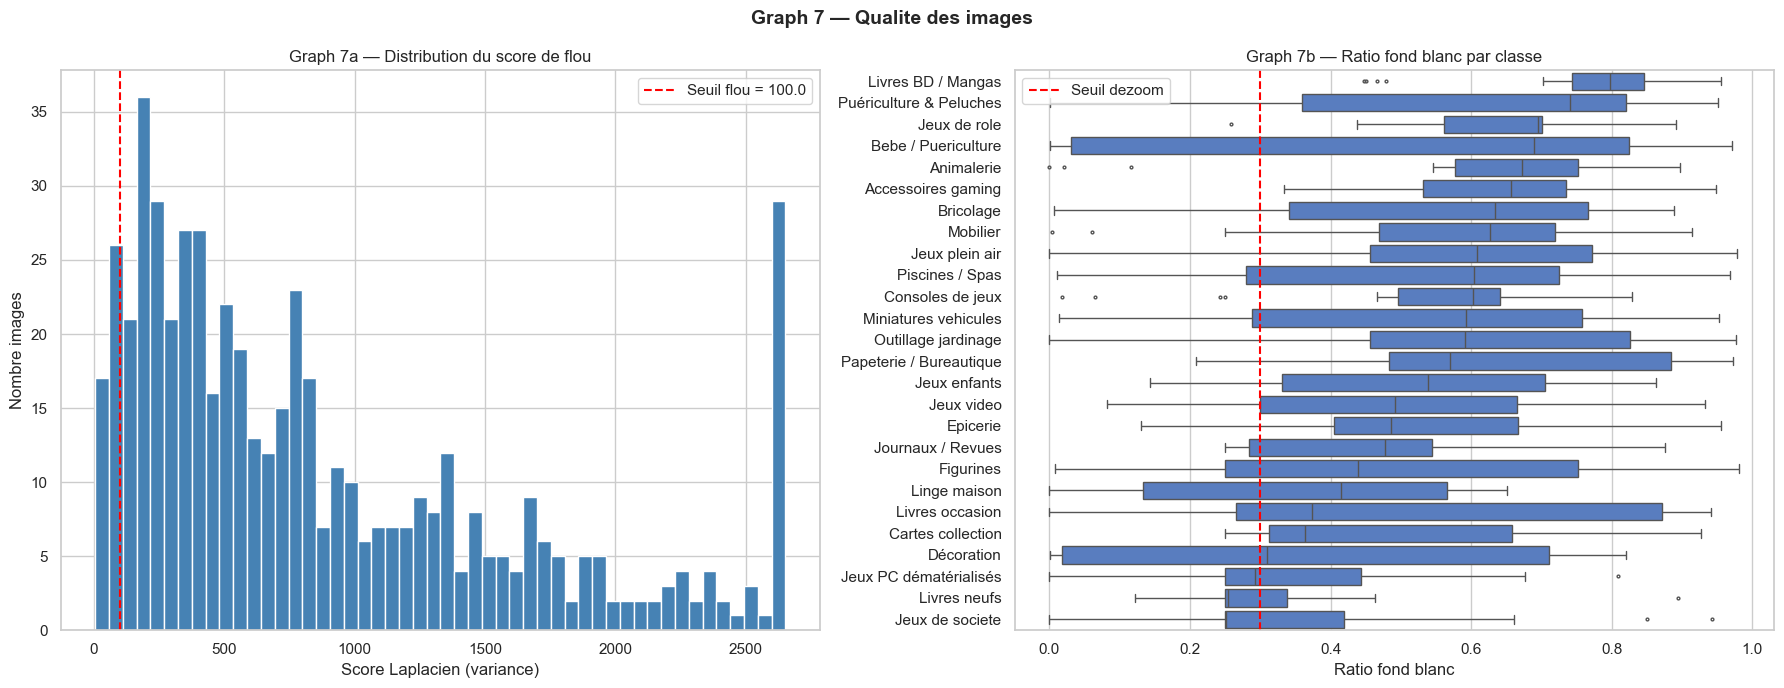

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Distribution scores de flou
blur_clean = blur_df['blur_score'].dropna()
axes[0].hist(blur_clean.clip(upper=blur_clean.quantile(0.95)), bins=50,
             color='steelblue', edgecolor='white')
axes[0].axvline(CFG['blur_threshold'], color='red', linestyle='--',
                label=f'Seuil flou = {CFG["blur_threshold"]}')
axes[0].set_xlabel('Score Laplacien (variance)')
axes[0].set_ylabel('Nombre images')
axes[0].set_title('Graph 7a — Distribution du score de flou')
axes[0].legend()

# Distribution ratio fond blanc par classe
order_white = blur_df.groupby('class_name')['white_ratio'].median().sort_values(ascending=False).index
sns.boxplot(data=blur_df, x='white_ratio', y='class_name', order=order_white, ax=axes[1], fliersize=2)
axes[1].axvline(1 - CFG['bg_ratio_thresh'], color='red', linestyle='--',
                label=f'Seuil dezoom')
axes[1].set_xlabel('Ratio fond blanc')
axes[1].set_title('Graph 7b — Ratio fond blanc par classe')
axes[1].set_ylabel('')
axes[1].legend()

plt.suptitle('Graph 7 — Qualite des images', fontsize=14, fontweight='bold')
plt.tight_layout()
save_fig('graph07_image_quality.png')
plt.show()

### 4.2 Auto-crop des images dezoomées

In [102]:
def auto_crop(img: Image.Image,
              bg_threshold: int = 240,
              margin_pct: float = 0.02) -> tuple[Image.Image, float]:
    """
    Detecte la zone de contenu (pixels non-blancs) et recadre l'image.

    Returns
    -------
    (img_cropped, zoom_ratio) ou (img_original, 1.0) si rien a recadrer.
    zoom_ratio = aire_contenu / aire_totale
    """
    img_arr = np.array(img.convert('RGB'))
    h, w = img_arr.shape[:2]
    is_bg = np.all(img_arr >= bg_threshold, axis=2)
    rows_content = np.where(~is_bg.all(axis=1))[0]
    cols_content = np.where(~is_bg.all(axis=0))[0]

    if len(rows_content) == 0 or len(cols_content) == 0:
        return img, 1.0  # image entierement blanche

    r_min, r_max = rows_content[0], rows_content[-1]
    c_min, c_max = cols_content[0], cols_content[-1]

    margin_r = int(h * margin_pct)
    margin_c = int(w * margin_pct)
    r_min = max(0, r_min - margin_r)
    r_max = min(h, r_max + margin_r)
    c_min = max(0, c_min - margin_c)
    c_max = min(w, c_max + margin_c)

    content_area = (r_max - r_min) * (c_max - c_min)
    zoom_ratio = content_area / (h * w)
    img_cropped = img.crop((c_min, r_min, c_max, r_max))
    return img_cropped, zoom_ratio

print('Fonction auto_crop definie.')

Fonction auto_crop definie.


2026-05-17 15:54:26,790 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph08_autocrop_examples.png


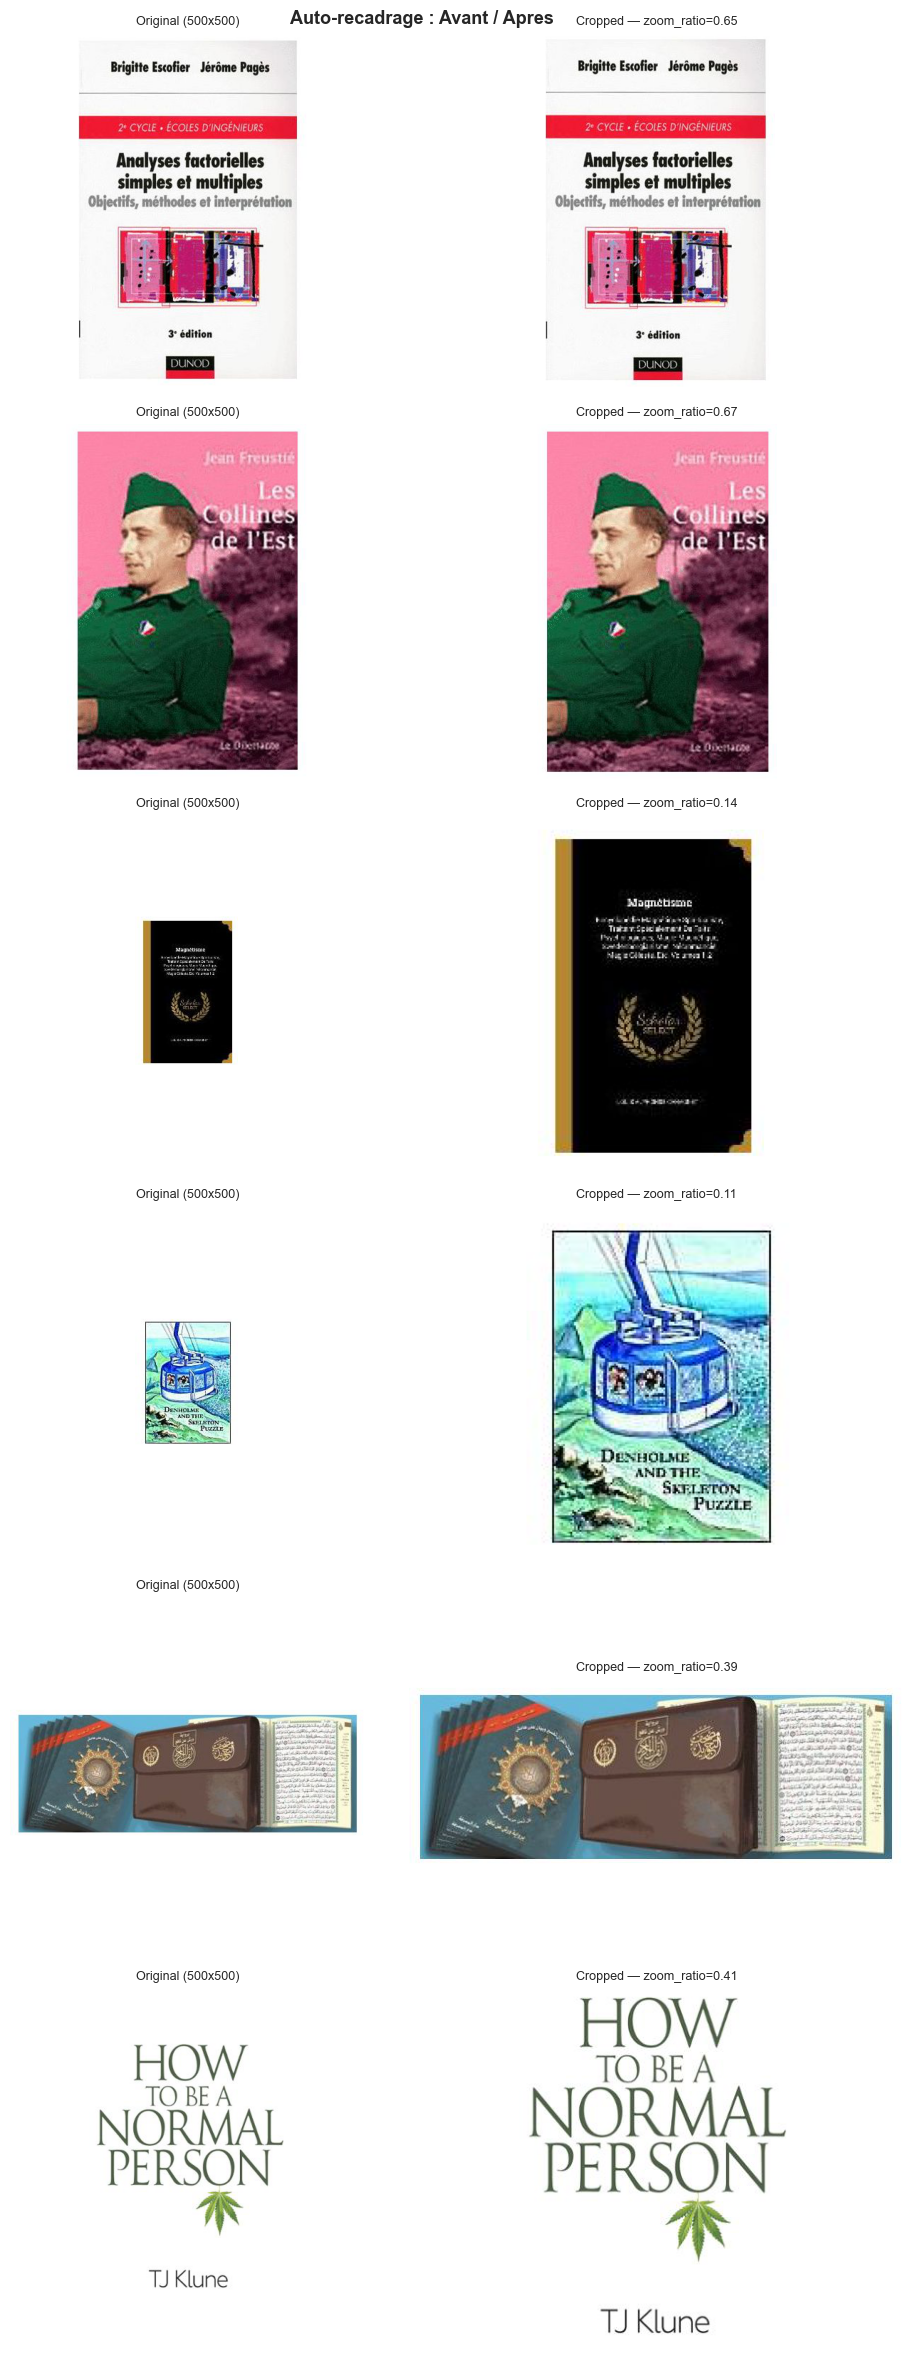

In [103]:
# Visualisation avant/apres sur les images les plus dezoomees de l'echantillon
dezoom_sample = blur_df[blur_df['white_ratio'] > 0.4].head(6)

if len(dezoom_sample) > 0:
    n_show = len(dezoom_sample)
    fig, axes = plt.subplots(n_show, 2, figsize=(10, n_show * 4))
    fig.suptitle('Auto-recadrage : Avant / Apres', fontsize=13, fontweight='bold')

    for i, (_, row) in enumerate(dezoom_sample.iterrows()):
        path = CFG['images_train'] / row['image_name']
        try:
            img = Image.open(path).convert('RGB')
            img_crop, zr = auto_crop(img, CFG['white_threshold'], CFG['crop_margin_pct'])
            axes[i, 0].imshow(img)
            axes[i, 0].set_title(f'Original ({img.size[0]}x{img.size[1]})', fontsize=9)
            axes[i, 1].imshow(img_crop)
            axes[i, 1].set_title(f'Cropped — zoom_ratio={zr:.2f}', fontsize=9)
            for ax in axes[i]:
                ax.axis('off')
        except Exception as e:
            pass

    plt.tight_layout()
    save_fig('graph08_autocrop_examples.png')
    plt.show()
else:
    print('Aucune image dezoomee dans cet echantillon.')

### 4.3 Scan complet des images + sauvegarde crops

> **Note** : Cette cellule traite ~84 916 images (10-20 min sur CPU).  
> Le résultat est mis en cache dans `processed_clean/image_scan.csv`.  
> Les images recadrées sont sauvegardées dans `processed_clean/image_crop/`.

In [104]:
SCAN_CACHE = CFG['processed'] / 'image_scan.csv'
DEZOOM_THRESHOLD = 1 / CFG['bg_ratio_thresh']  # zoom_ratio < 0.70 => dezoomee

if SCAN_CACHE.exists():
    scan_df = pd.read_csv(SCAN_CACHE)
    print(f'Cache charge : {len(scan_df)} images')
else:
    print('Scan complet en cours...')
    records = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc='Scan images'):
        path = CFG['images_train'] / row['image_name']
        zoom_ratio = np.nan
        blur = np.nan
        if path.exists():
            try:
                img = Image.open(path).convert('RGB')
                _, zoom_ratio = auto_crop(img, CFG['white_threshold'], CFG['crop_margin_pct'])
                blur = compute_blur_score(path)
            except Exception:
                pass
        records.append({
            'image_name':  row['image_name'],
            'class_name':  row['class_name'],
            'prdtypecode': row['prdtypecode'],
            'zoom_ratio':  zoom_ratio,
            'blur_score':  blur,
            'is_dezoom':   int(zoom_ratio < CFG['bg_ratio_thresh']) if not np.isnan(zoom_ratio) else 0,
        })
    scan_df = pd.DataFrame(records)
    scan_df.to_csv(SCAN_CACHE, index=False)
    print(f'Cache sauvegarde : {SCAN_CACHE}')

pct_dezoom = scan_df['is_dezoom'].mean() * 100
print(f'Images dezoomees (zoom_ratio < {CFG["bg_ratio_thresh"]}) : {pct_dezoom:.1f}%')

Scan complet en cours...


Scan images: 100%|██████████| 84916/84916 [13:17<00:00, 106.47it/s]


Cache sauvegarde : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed_clean\image_scan.csv
Images dezoomees (zoom_ratio < 0.7) : 48.6%


In [105]:
# Sauvegarde des images recadrees (uniquement si dezoomees)
CROP_DIR = CFG['processed'] / 'image_crop'
CROP_DIR.mkdir(parents=True, exist_ok=True)

n_saved = 0
n_copied = 0
for _, row in tqdm(scan_df.iterrows(), total=len(scan_df), desc='Sauvegarde crops'):
    src = CFG['images_train'] / row['image_name']
    dst = CROP_DIR / row['image_name']
    if dst.exists() or not src.exists():
        continue
    try:
        img = Image.open(src).convert('RGB')
        if row['is_dezoom']:
            img_out, _ = auto_crop(img, CFG['white_threshold'], CFG['crop_margin_pct'])
            n_saved += 1
        else:
            img_out = img
            n_copied += 1
        img_out.save(dst)
    except Exception:
        pass

print(f'Images recadrees sauvegardees : {n_saved}')
print(f'Images copiees sans crop      : {n_copied}')

Sauvegarde crops: 100%|██████████| 84916/84916 [10:39<00:00, 132.86it/s] 

Images recadrees sauvegardees : 41257
Images copiees sans crop      : 43659


In [106]:
# Fusionner zoom_ratio et blur_score dans le DataFrame principal
df = df.merge(scan_df[['image_name', 'zoom_ratio', 'blur_score', 'is_dezoom']],
              on='image_name', how='left')
df['zoom_ratio'] = df['zoom_ratio'].fillna(1.0)
df['blur_score'] = df['blur_score'].fillna(df['blur_score'].median())
print(f'Colonnes ajoutees : zoom_ratio, blur_score, is_dezoom')
print(df[['zoom_ratio', 'blur_score', 'is_dezoom']].describe())

Colonnes ajoutees : zoom_ratio, blur_score, is_dezoom
         zoom_ratio    blur_score     is_dezoom
count  84916.000000  84916.000000  84916.000000
mean       0.654235    929.071379      0.485857
std        0.250078   1101.470529      0.499803
min        0.007392      0.000000      0.000000
25%        0.500397    276.169144      0.000000
50%        0.706000    597.024078      0.000000
75%        0.816067   1198.573273      1.000000
max        1.000000  38180.863281      1.000000


---
## 5. Pipeline de Preprocessing Texte

### 5.1 Nettoyage HTML

In [107]:
_HTML_TAG     = re.compile(r'<[^>]+>', re.IGNORECASE)
_HTML_ENTITY  = re.compile(r'&[a-zA-Z]+;|&#\d+;')
_MULTIPLE_SPC = re.compile(r'\s+')

def clean_html(text: str) -> str:
    """Supprime les balises HTML et entites, normalise les espaces."""
    if pd.isna(text):
        return ''
    text = _HTML_TAG.sub(' ', str(text))
    text = _HTML_ENTITY.sub(' ', text)
    return _MULTIPLE_SPC.sub(' ', text).strip()

# Verification : nombre de cellules avec HTML
n_html_desig = df['designation'].str.contains(_HTML_TAG, regex=True, na=False).sum()
n_html_desc  = df['description'].str.contains(_HTML_TAG, regex=True, na=False).sum()
print(f'HTML dans designation : {n_html_desig} ({n_html_desig/len(df)*100:.1f}%)')
print(f'HTML dans description : {n_html_desc} ({n_html_desc/len(df)*100:.1f}%)')

df['designation_html_clean'] = df['designation'].apply(clean_html)
df['description_html_clean'] = df['description'].apply(clean_html)

HTML dans designation : 1 (0.0%)
HTML dans description : 15645 (18.4%)


### 5.2 Colonne `combined_raw` — Version brute pour les Transformers

> **IMPORTANT** : Cette colonne est conservée **sans aucune transformation** (hors nettoyage HTML).  
> Elle sera utilisée par CamemBERT, multilingual-e5-large, et les modèles CLIP.  
> Les tokenizers gèrent eux-mêmes les stop words et la casse.

In [108]:
df['combined_raw'] = (
    df['designation_html_clean'].fillna('') + ' ' +
    df['description_html_clean'].fillna('')
).str.strip()

print('Colonne combined_raw cree (designation + description, HTML nettoye, aucun autre traitement)')
print(df[['designation', 'combined_raw']].head(3))

Colonne combined_raw cree (designation + description, HTML nettoye, aucun autre traitement)
                                         designation  \
0  Olivia: Personalisiertes Notizbuch / 150 Seite...   
1  Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...   
2  Grand Stylet Ergonomique Bleu Gamepad Nintendo...   

                                        combined_raw  
0  Olivia: Personalisiertes Notizbuch / 150 Seite...  
1  Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...  
2  Grand Stylet Ergonomique Bleu Gamepad Nintendo...  


### 5.3 Pipeline de nettoyage (Baseline ML)

Pour la branche baseline (TF-IDF + LightGBM) :
- Minuscules
- Suppression des chiffres et caractères spéciaux
- Suppression stop words multilingues (FR/EN/DE/ES)
- Stemming SnowballFR (français dominante)

In [109]:
stemmer_fr = SnowballStemmer('french')
_NON_ALPHA = re.compile(r'[^a-z\s]')

def preprocess_text(text: str, stem: bool = True) -> str:
    """
    Pipeline baseline : minuscules → suppression non-alpha → stop words → stemming.

    Parameters
    ----------
    text : str
    stem : bool — applique le stemming Snowball FR si True
    """
    if pd.isna(text) or not str(text).strip():
        return ''
    text = str(text).lower()
    text = _NON_ALPHA.sub(' ', text)
    tokens = text.split()
    tokens = [t for t in tokens if t not in all_stopwords and len(t) > 2]
    if stem:
        tokens = [stemmer_fr.stem(t) for t in tokens]
    return ' '.join(tokens)

print('Application du preprocessing texte...')
df['designation_clean'] = df['designation_html_clean'].progress_apply(preprocess_text)
df['description_clean'] = df['description_html_clean'].progress_apply(preprocess_text)
df['text_combined']     = (
    df['designation_clean'].fillna('') + ' ' +
    df['description_clean'].fillna('')
).str.strip()

print('OK')
df[['designation', 'designation_clean', 'text_combined']].head(3)

Application du preprocessing texte...


100%|██████████| 84916/84916 [00:23<00:00, 3543.02it/s]

OK


,designation,designation_clean,text_combined
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,olivi personalisiert notizbuch seiten punktras...,olivi personalisiert notizbuch seiten punktras...
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,journal art art march salon art asiat paris ja...,journal art art march salon art asiat paris ja...
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,grand stylet ergonom bleu gamepad nintendo wii...,grand stylet ergonom bleu gamepad nintendo wii...


2026-05-17 16:18:54,522 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph_A_avant_apres_preprocessing.png


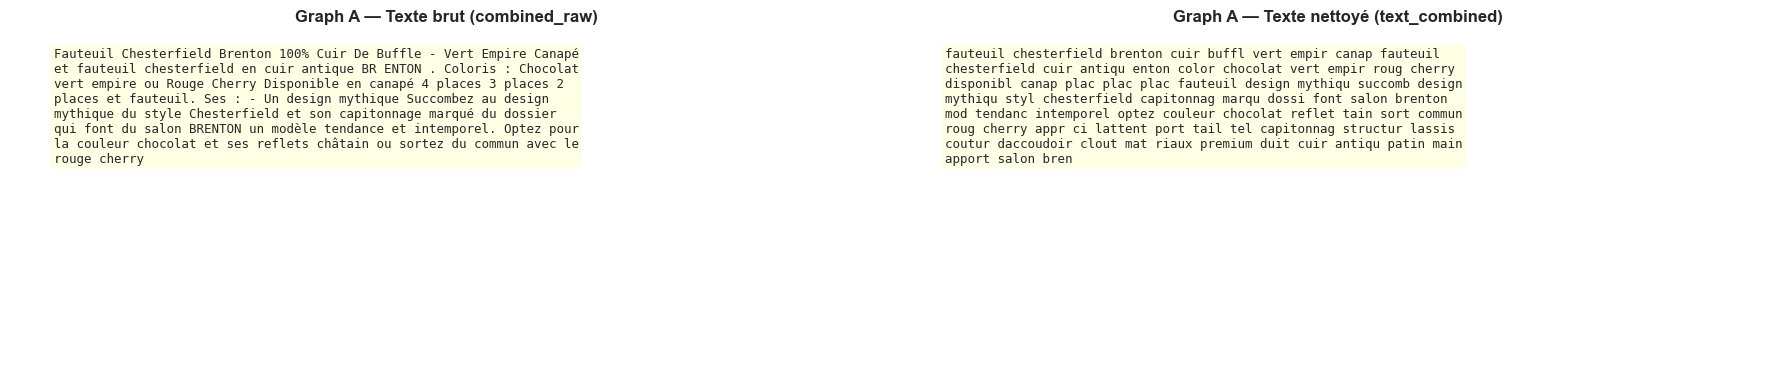

2026-05-17 16:18:56,606 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph_B_length_distribution.png


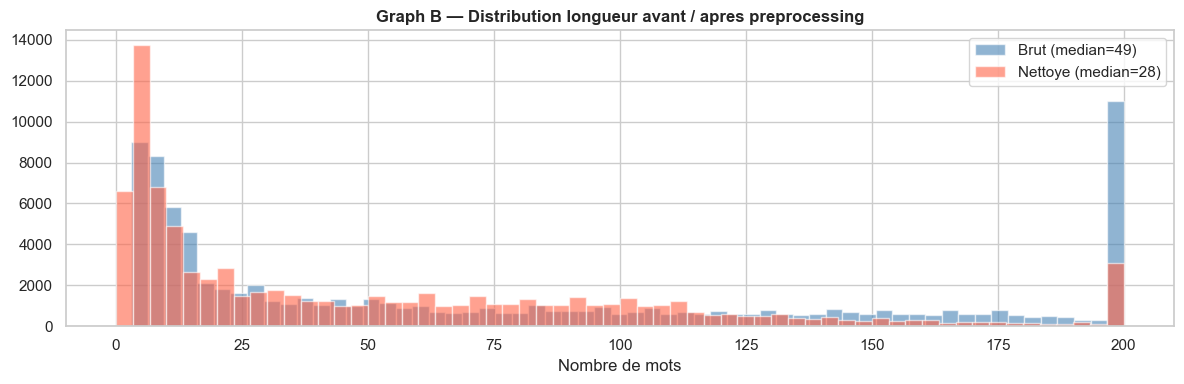

Graph C — Vocabulaire brut : 291,299 mots
          Vocabulaire nettoye : 90,887 mots (-69%)


In [110]:
# --- Visualisation avant / apres preprocessing ---
sample_idx = df[df['has_desc'] == 1].index[5]
raw_text   = df.loc[sample_idx, 'combined_raw']
clean_text = df.loc[sample_idx, 'text_combined']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 4))
for ax, text, title in [(ax1, raw_text, 'Texte brut (combined_raw)'),
                         (ax2, clean_text, 'Texte nettoyé (text_combined)')]:
    wrapped = textwrap.fill(text[:500], width=70)
    ax.text(0.05, 0.95, wrapped, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', fontfamily='monospace',
            wrap=True, bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    ax.set_title(f'Graph A — {title}', fontweight='bold')
    ax.axis('off')
plt.tight_layout()
save_fig('graph_A_avant_apres_preprocessing.png')
plt.show()

# Distribution de la longueur avant/apres
len_raw   = (df['designation_html_clean'].fillna('') + ' ' + df['description_html_clean'].fillna('')).str.split().str.len()
len_clean = df['text_combined'].str.split().str.len()

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(len_raw.clip(upper=200), bins=60, alpha=0.6, label=f'Brut (median={len_raw.median():.0f})', color='steelblue')
ax.hist(len_clean.clip(upper=200), bins=60, alpha=0.6, label=f'Nettoye (median={len_clean.median():.0f})', color='tomato')
ax.set_xlabel('Nombre de mots')
ax.set_title('Graph B — Distribution longueur avant / apres preprocessing', fontweight='bold')
ax.legend()
plt.tight_layout()
save_fig('graph_B_length_distribution.png')
plt.show()

vocab_raw   = set(w for txt in len_raw.index.map(lambda i: df.loc[i, 'designation_html_clean'] + ' ' + df.loc[i, 'description_html_clean']).str.lower() for w in str(txt).split())
vocab_clean = set(w for txt in df['text_combined'].str.lower() for w in str(txt).split() if w)
print(f'Graph C — Vocabulaire brut : {len(vocab_raw):,} mots')
print(f'          Vocabulaire nettoye : {len(vocab_clean):,} mots (-{(1-len(vocab_clean)/len(vocab_raw))*100:.0f}%)')

---
## 6. Encodage des Labels et Split Train/Val/Test

### 6.1 LabelEncoder

Les codes `prdtypecode` sont non-consécutifs (10, 40, 50… 2905).  
On les encode en entiers consécutifs 0–26 pour PyTorch et sklearn.

In [111]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['prdtypecode'])

label_mapping = dict(zip(le.classes_.tolist(), le.transform(le.classes_).tolist()))
label_mapping_inv = {v: k for k, v in label_mapping.items()}

# Sauvegarde du LabelEncoder
with open(CFG['models_dir'] / 'label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

print(f'Classes encodees : {len(label_mapping)}')
print(f'Exemple : prdtypecode {list(label_mapping.keys())[:5]} -> labels {list(label_mapping.values())[:5]}')

Classes encodees : 27
Exemple : prdtypecode [10, 40, 50, 60, 1140] -> labels [0, 1, 2, 3, 4]


### 6.2 Split stratifié (70 / 15 / 15)

In [112]:
# Colonnes a conserver dans les splits
COLS_EXPORT = [
    'productid', 'imageid', 'image_name',
    'designation', 'description',         # textes originaux (apres clean HTML)
    'combined_raw',                         # texte brut pour Transformers
    'text_combined',                        # texte nettoye pour TF-IDF / baseline
    'designation_clean', 'description_clean',
    'language', 'has_desc',
    'len_desig', 'len_desc',
    'zoom_ratio', 'blur_score', 'is_dezoom',
    'prdtypecode', 'class_name', 'label',
]

train_df, tmp_df = train_test_split(
    df[COLS_EXPORT],
    test_size=CFG['val_size'] + CFG['test_size'],
    stratify=df['label'],
    random_state=CFG['random_state'],
)
val_df, test_df = train_test_split(
    tmp_df,
    test_size=CFG['test_size'] / (CFG['val_size'] + CFG['test_size']),
    stratify=tmp_df['label'],
    random_state=CFG['random_state'],
)

print(f'Train : {len(train_df):,} ({len(train_df)/len(df)*100:.1f}%)')
print(f'Val   : {len(val_df):,}   ({len(val_df)/len(df)*100:.1f}%)')
print(f'Test  : {len(test_df):,}  ({len(test_df)/len(df)*100:.1f}%)')

Train : 59,441 (70.0%)
Val   : 12,737   (15.0%)
Test  : 12,738  (15.0%)


2026-05-17 16:19:00,549 INFO Figure sauvegardee : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\graph09_split_verification.png


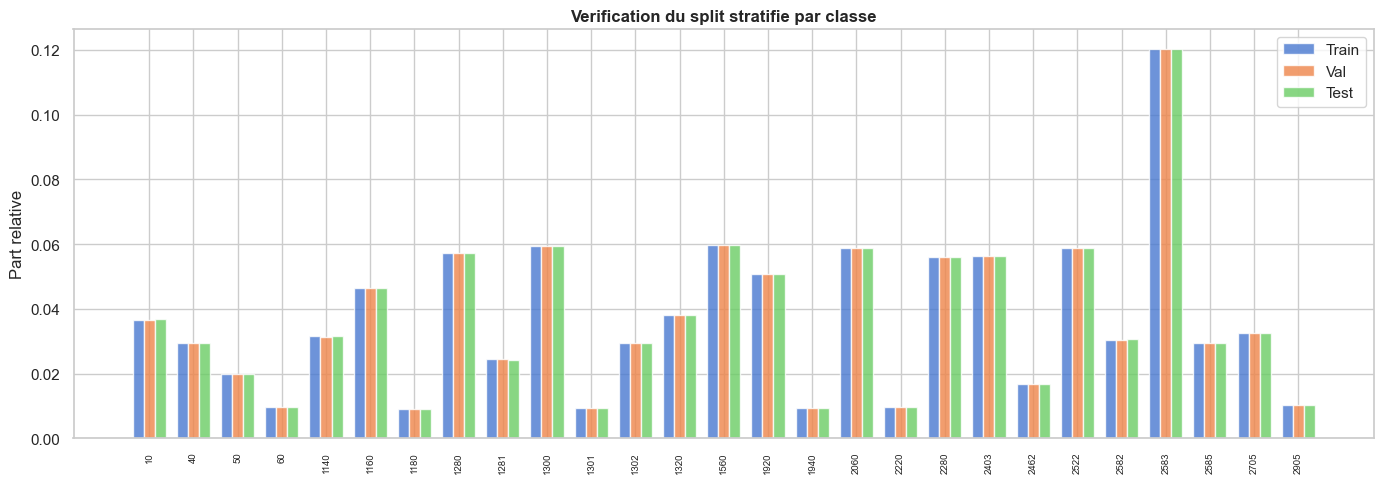

In [113]:
# Verification du split stratifie
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(CFG['n_classes'])
w = 0.25
for i, (split, split_df) in enumerate([('Train', train_df), ('Val', val_df), ('Test', test_df)]):
    counts = split_df['label'].value_counts().sort_index()
    ax.bar(x + i * w, counts.values / len(split_df), width=w, label=split, alpha=0.8)
ax.set_xticks(x + w)
ax.set_xticklabels([label_mapping_inv[i] for i in range(CFG['n_classes'])], rotation=90, fontsize=7)
ax.set_ylabel('Part relative')
ax.set_title('Verification du split stratifie par classe', fontweight='bold')
ax.legend()
plt.tight_layout()
save_fig('graph09_split_verification.png')
plt.show()

### 6.3 Class Weights

In [114]:
classes  = np.sort(train_df['label'].unique())
weights  = compute_class_weight('balanced', classes=classes, y=train_df['label'].values)
class_weight_dict = dict(zip(classes.tolist(), weights.tolist()))

np.save(CFG['processed'] / 'class_weights.npy', weights)

print('Class weights (extrait) :')
for cls, w in sorted(class_weight_dict.items())[:5]:
    print(f'  label={cls} (prdtypecode={label_mapping_inv[cls]}) : weight={w:.3f}')

Class weights (extrait) :
  label=0 (prdtypecode=10) : weight=1.009
  label=1 (prdtypecode=40) : weight=1.254
  label=2 (prdtypecode=50) : weight=1.870
  label=3 (prdtypecode=60) : weight=3.783
  label=4 (prdtypecode=1140) : weight=1.177


---
## 7. Export des données

### 7.1 Splits CSV

In [115]:
for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    out_path = CFG['split_dir'] / f'{split_name}.csv'
    split_df.to_csv(out_path, index=False)
    print(f'Sauvegarde : {out_path} ({len(split_df):,} lignes, {len(split_df.columns)} colonnes)')

# Labels numpy
for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    np.save(CFG['processed'] / f'y_{split_name}.npy', split_df['label'].values)
    print(f'y_{split_name}.npy sauvegarde')

Sauvegarde : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\split_no_crop2\train.csv (59,441 lignes, 19 colonnes)
Sauvegarde : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\split_no_crop2\val.csv (12,737 lignes, 19 colonnes)
Sauvegarde : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\split_no_crop2\test.csv (12,738 lignes, 19 colonnes)
y_train.npy sauvegarde
y_val.npy sauvegarde
y_test.npy sauvegarde


### 7.2 Copy images vers split_no_crop/{train,val,test}/

In [116]:
import shutil

for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    dst_dir = CFG['split_dir'] / split_name
    dst_dir.mkdir(parents=True, exist_ok=True)
    n_ok = 0
    for img_name in tqdm(split_df['image_name'], desc=f'Copy images {split_name}', leave=False):
        src = CFG['images_train'] / img_name
        dst = dst_dir / img_name
        if src.exists() and not dst.exists():
            shutil.copy2(src, dst)
            n_ok += 1
    print(f'{split_name}: {n_ok} images copiees dans {dst_dir}')

train: 59441 images copiees dans c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\split_no_crop2\train


val: 12737 images copiees dans c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\split_no_crop2\val


test: 12738 images copiees dans c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\split_no_crop2\test


---
## 8. Récapitulatif Final

In [117]:
print('=' * 60)
print('  NOTEBOOK 1 — BILAN PREPROCESSING & EDA')
print('=' * 60)
print()
print('DATASET')
print(f'  Total produits   : {len(df):,}')
print(f'  Classes          : {df["prdtypecode"].nunique()}')
print(f'  Desc. manquantes : {df["has_desc"].eq(0).mean()*100:.1f}%')
print(f'  Langue FR        : {(df["language"]=="fr").mean()*100:.1f}%')
print()
print('SPLITS')
print(f'  Train : {len(train_df):,}  Val : {len(val_df):,}  Test : {len(test_df):,}')
print()
print('COLONNES CLES EXPORTEES')
print(f'  combined_raw     : texte brut (designation + description HTML-clean) — pour Transformers')
print(f'  text_combined    : texte nettoyé (stopwords + stemming) — pour TF-IDF baseline')
print(f'  zoom_ratio       : ratio contenu/fond (auto-crop quality metric)')
print(f'  blur_score       : variance Laplacien (sharpness metric)')
print(f'  label            : classe encodee 0-26 (LabelEncoder sauvegarde)')
print()
print('FICHIERS GENERES')
generated = [
    CFG['split_dir'] / 'train.csv',
    CFG['split_dir'] / 'val.csv',
    CFG['split_dir'] / 'test.csv',
    CFG['processed'] / 'y_train.npy',
    CFG['processed'] / 'y_val.npy',
    CFG['processed'] / 'y_test.npy',
    CFG['processed'] / 'class_weights.npy',
    CFG['processed'] / 'image_scan.csv',
    CFG['processed'] / 'stats_par_classe.csv',
    CFG['models_dir'] / 'label_encoder.pkl',
]
for p in generated:
    status = 'OK' if p.exists() else 'MANQUANT'
    print(f'  [{status}] {p.relative_to(CFG["root"])}')

print()
print('PROCHAIN NOTEBOOK : 02_baseline_multimodale.ipynb')
print('  Charge train.csv / val.csv / test.csv')
print('  TF-IDF baseline + image features + LightGBM')

  NOTEBOOK 1 — BILAN PREPROCESSING & EDA

DATASET
  Total produits   : 84,916
  Classes          : 27
  Desc. manquantes : 35.1%
  Langue FR        : 77.7%

SPLITS
  Train : 59,441  Val : 12,737  Test : 12,738

COLONNES CLES EXPORTEES
  combined_raw     : texte brut (designation + description HTML-clean) — pour Transformers
  text_combined    : texte nettoyé (stopwords + stemming) — pour TF-IDF baseline
  zoom_ratio       : ratio contenu/fond (auto-crop quality metric)
  blur_score       : variance Laplacien (sharpness metric)
  label            : classe encodee 0-26 (LabelEncoder sauvegarde)

FICHIERS GENERES
  [OK] data\split_no_crop2\train.csv
  [OK] data\split_no_crop2\val.csv
  [OK] data\split_no_crop2\test.csv
  [OK] data\processed_clean\y_train.npy
  [OK] data\processed_clean\y_val.npy
  [OK] data\processed_clean\y_test.npy
  [OK] data\processed_clean\class_weights.npy
  [OK] data\processed_clean\image_scan.csv
  [OK] data\processed_clean\stats_par_classe.csv
  [OK] models\clean